# Causal Marketing Allocation — Incremental Profit Under Budget Constraints

## Executive Summary

This project develops a causal machine learning framework for marketing allocation using the randomized Hillstrom email experiment.

The goal is not simply to predict **who will purchase**, but to estimate **whose behaviour changes because of a marketing intervention**, and then convert those treatment-effect estimates into a budget-constrained business policy.

The analysis preserves the original three decision options:

- No E-Mail
- Mens E-Mail
- Womens E-Mail

The project separates three different tasks:

1. **Experimental inference** — estimate average treatment effects from the randomized experiment.
2. **Causal model selection** — compare heterogeneous treatment-effect learners on a validation sample.
3. **Final policy evaluation** — evaluate the selected targeting policies on a final randomized test sample that is excluded from model fitting and model selection.

The final decision problem is:

> Given a limited campaign budget, which customers should receive which email treatment in order to maximize incremental profit?

## Business Problem

Traditional response modelling asks:

> Who is most likely to buy?

That question can be misleading for intervention decisions. A customer with a high purchase probability may have purchased even without receiving an email.

Causal modelling instead asks:

> Whose outcome is expected to change because of the treatment?

For each customer, the business can choose one of three actions:

1. Send no email.
2. Send the Mens email.
3. Send the Womens email.

### Primary objective

Estimate customer-level incremental value and allocate treatment under explicit campaign-cost and contact-budget assumptions.

### Secondary objectives

- Validate the randomized experimental design.
- Estimate average treatment effects with uncertainty intervals.
- Compare T-Learner, X-Learner and DR-Learner approaches.
- Validate CATE ranking on held-out randomized data.
- Compare predictive response targeting with causal targeting.
- Evaluate profit-aware policies using off-policy evaluation on randomized test data.
- Stress-test causal estimators under deliberately induced observational confounding.

## Environment Setup

The notebook uses a small causal-ML stack. `econml` is used for the X-Learner and DR-Learner. Qini / cumulative-gain calculations are implemented directly in the notebook to avoid dependency issues and to make the evaluation logic transparent.

In [ ]:
!pip install -q econml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 43.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.3/155.3 kB 9.3 MB/s eta 0:00:00


## Imports

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.special import expit

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    GradientBoostingClassifier,
)
from sklearn.metrics import roc_auc_score

from econml.metalearners import XLearner
from econml.dr import DRLearner

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## Data Source and Experimental Design

This project uses the Hillstrom Email Marketing dataset. Approximately 64,000 customers were randomly assigned to one of three conditions:

- No E-Mail
- Mens E-Mail
- Womens E-Mail

The available pre-treatment variables include historical customer behaviour, product history, geography category and purchase channel. Post-treatment outcomes include `visit`, `conversion` and `spend`.

Only variables measured before treatment assignment are used as model features.

In [ ]:
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "W-Tran/uplift-modelling/master/data/hillstrom/"
    "Kevin_Hillstrom_MineThatData_E-MailAnalytics_"
    "DataMiningChallenge_2008.03.20.csv"
)

df = pd.read_csv(DATA_URL)

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
df.head()

Dataset loaded successfully.
Rows: 64,000
Columns: 12


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000
2,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000


## Data Quality Audit

In [ ]:
print("Shape:")
display(df.shape)

print("\nColumn types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isna().sum().to_frame("Missing"))

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTreatment groups:")
display(
    df["segment"]
    .value_counts()
    .rename_axis("Treatment")
    .to_frame("Customers")
)

Shape:


(64000, 12)


Column types:


,dtype
recency,int64
history_segment,object
history,float64
mens,int64
womens,int64
zip_code,object
newbie,int64
channel,object
segment,object
visit,int64



Missing values:


,Missing
recency,0
history_segment,0
history,0
mens,0
womens,0
zip_code,0
newbie,0
channel,0
segment,0
visit,0



Duplicate rows:
6562

Treatment groups:


,Customers
Treatment,
Womens E-Mail,21387
Mens E-Mail,21307
No E-Mail,21306


### Duplicate Row Note

Exact duplicate rows are retained because the public dataset does not include a unique customer identifier; identical observed records may therefore represent distinct customers.

## Define Causal Roles and Leakage Guard

In [ ]:
TREATMENT_COL = "segment"
OUTCOME_COLS = ["visit", "conversion", "spend"]

NUMERIC_FEATURES = [
    "recency",
    "history",
    "mens",
    "womens",
    "newbie",
]

CATEGORICAL_FEATURES = [
    "history_segment",
    "zip_code",
    "channel",
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

post_treatment_variables = {"visit", "conversion", "spend"}
leakage_features = set(FEATURES).intersection(post_treatment_variables)

assert not leakage_features, f"Post-treatment leakage detected: {leakage_features}"

print("Leakage check passed.")
print("Treatment:", TREATMENT_COL)
print("Outcomes:", OUTCOME_COLS)
print("Pre-treatment features:", FEATURES)

Leakage check passed.
Treatment: segment
Outcomes: ['visit', 'conversion', 'spend']
Pre-treatment features: ['recency', 'history', 'mens', 'womens', 'newbie', 'history_segment', 'zip_code', 'channel']


## Treatment Distribution

Treatment,Customers,Share
Womens E-Mail,"21,387",33.42%
Mens E-Mail,"21,307",33.29%
No E-Mail,"21,306",33.29%


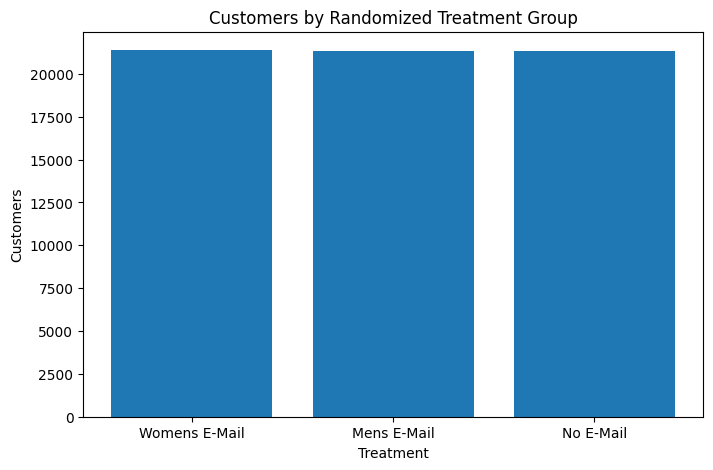

In [ ]:
treatment_summary = (
    df["segment"]
    .value_counts()
    .rename_axis("Treatment")
    .reset_index(name="Customers")
)

treatment_summary["Share"] = (
    treatment_summary["Customers"] / treatment_summary["Customers"].sum()
)

display(
    treatment_summary.style
    .format({"Customers": "{:,.0f}", "Share": "{:.2%}"})
    .hide(axis="index")
)

plt.figure(figsize=(8, 5))
plt.bar(treatment_summary["Treatment"], treatment_summary["Customers"])
plt.title("Customers by Randomized Treatment Group")
plt.xlabel("Treatment")
plt.ylabel("Customers")
plt.show()

## Descriptive Outcome Summary

In [ ]:
outcome_summary = (
    df.groupby("segment")
    .agg(
        Customers=("segment", "size"),
        Visit_Rate=("visit", "mean"),
        Conversion_Rate=("conversion", "mean"),
        Average_Spend=("spend", "mean"),
    )
    .reset_index()
)

display(
    outcome_summary.style
    .format({
        "Customers": "{:,.0f}",
        "Visit_Rate": "{:.2%}",
        "Conversion_Rate": "{:.2%}",
        "Average_Spend": "${:,.2f}",
    })
    .hide(axis="index")
)

segment,Customers,Visit_Rate,Conversion_Rate,Average_Spend
Mens E-Mail,"21,307",18.28%,1.25%,$1.42
No E-Mail,"21,306",10.62%,0.57%,$0.65
Womens E-Mail,"21,387",15.14%,0.88%,$1.08


## Randomization Validation

Random assignment should produce similar pre-treatment covariate distributions across treatment arms. Numeric balance is assessed with standardized mean differences (SMDs); categorical distributions are compared directly.

A common rule of thumb is that absolute SMD values below 0.10 indicate acceptable balance.

segment,Mens E-Mail,No E-Mail,Womens E-Mail
recency,5.7736,5.7497,5.7678
history,242.8359,240.8827,242.5366
mens,0.5509,0.5532,0.5489
womens,0.5514,0.5476,0.5501
newbie,0.5015,0.5020,0.5032


Treatment,Feature,SMD
Mens E-Mail,recency,0.0068
Mens E-Mail,history,0.0076
Mens E-Mail,mens,-0.0046
Mens E-Mail,womens,0.0076
Mens E-Mail,newbie,-0.0009
Womens E-Mail,recency,0.0052
Womens E-Mail,history,0.0065
Womens E-Mail,mens,-0.0086
Womens E-Mail,womens,0.0049
Womens E-Mail,newbie,0.0026


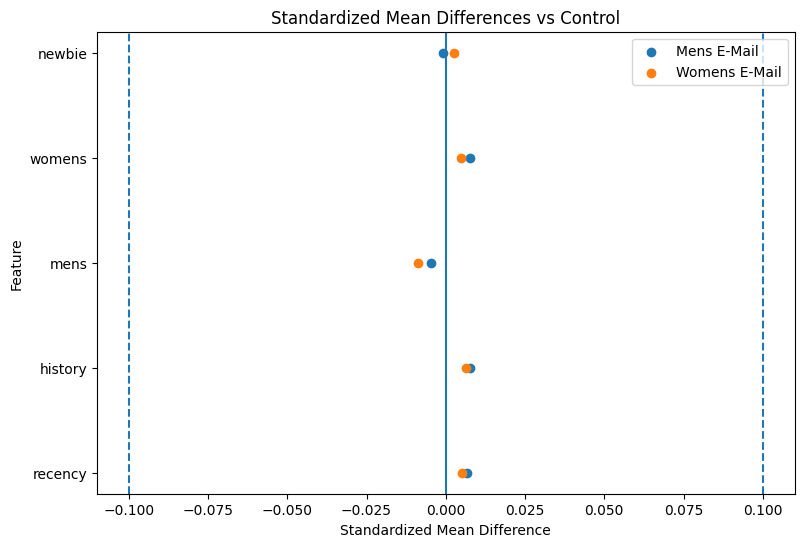

In [ ]:
CONTROL = "No E-Mail"
TREATMENTS = ["Mens E-Mail", "Womens E-Mail"]

balance_numeric = df.groupby("segment")[NUMERIC_FEATURES].mean().T
display(balance_numeric.style.format("{:.4f}"))


def standardized_mean_difference(data, feature, treatment, control=CONTROL):
    treated = data.loc[data["segment"] == treatment, feature].astype(float)
    control_group = data.loc[data["segment"] == control, feature].astype(float)

    pooled_sd = np.sqrt(
        (treated.var(ddof=1) + control_group.var(ddof=1)) / 2
    )

    if pooled_sd == 0:
        return 0.0

    return (treated.mean() - control_group.mean()) / pooled_sd


smd_results = []
for treatment in TREATMENTS:
    for feature in NUMERIC_FEATURES:
        smd_results.append({
            "Treatment": treatment,
            "Feature": feature,
            "SMD": standardized_mean_difference(df, feature, treatment),
        })

smd_table = pd.DataFrame(smd_results)

display(
    smd_table.style
    .format({"SMD": "{:.4f}"})
    .hide(axis="index")
)

plt.figure(figsize=(9, 6))
for treatment in TREATMENTS:
    subset = smd_table[smd_table["Treatment"] == treatment]
    plt.scatter(subset["SMD"], subset["Feature"], label=treatment)

plt.axvline(0.10, linestyle="--")
plt.axvline(-0.10, linestyle="--")
plt.axvline(0, linestyle="-")
plt.title("Standardized Mean Differences vs Control")
plt.xlabel("Standardized Mean Difference")
plt.ylabel("Feature")
plt.legend()
plt.show()

In [ ]:
for feature in CATEGORICAL_FEATURES:
    balance = pd.crosstab(
        df[feature],
        df["segment"],
        normalize="columns",
    )

    print(f"\nBalance for: {feature}")
    display((balance * 100).style.format("{:.2f}%"))


Balance for: history_segment


segment,Mens E-Mail,No E-Mail,Womens E-Mail
history_segment,,,
1) $0 - $100,36.25%,35.73%,35.69%
2) $100 - $200,22.02%,22.70%,22.10%
3) $200 - $350,19.20%,18.98%,19.43%
4) $350 - $500,9.84%,9.97%,10.23%
5) $500 - $750,7.50%,7.75%,7.77%
"6) $750 - $1,000",3.02%,2.92%,2.77%
"7) $1,000 +",2.18%,1.95%,2.00%



Balance for: zip_code


segment,Mens E-Mail,No E-Mail,Womens E-Mail
zip_code,,,
Rural,15.22%,14.73%,14.87%
Surburban,44.59%,45.18%,45.12%
Urban,40.19%,40.09%,40.01%



Balance for: channel


segment,Mens E-Mail,No E-Mail,Womens E-Mail
channel,,,
Multichannel,12.09%,12.23%,12.06%
Phone,43.37%,43.78%,44.20%
Web,44.54%,43.99%,43.74%


### Randomization Check

If numeric SMDs are close to zero and categorical distributions are similar across arms, the observed balance is consistent with successful randomization. This supports direct experimental treatment-control comparisons for average treatment effects.

## Average Treatment Effects from the Randomized Experiment

In [ ]:
def ate_difference_in_means(
    data,
    outcome,
    treatment,
    control=CONTROL,
    alpha=0.05,
):
    treated = data.loc[data["segment"] == treatment, outcome].astype(float)
    control_group = data.loc[data["segment"] == control, outcome].astype(float)

    ate = treated.mean() - control_group.mean()
    se = np.sqrt(
        treated.var(ddof=1) / len(treated)
        + control_group.var(ddof=1) / len(control_group)
    )

    z = stats.norm.ppf(1 - alpha / 2)

    return {
        "ATE": ate,
        "SE": se,
        "CI Lower": ate - z * se,
        "CI Upper": ate + z * se,
    }


ate_results = []
for treatment in TREATMENTS:
    for outcome in OUTCOME_COLS:
        result = ate_difference_in_means(df, outcome, treatment)
        ate_results.append({
            "Treatment": treatment,
            "Outcome": outcome,
            **result,
        })

ate_table = pd.DataFrame(ate_results)

display(
    ate_table.style
    .format({
        "ATE": "{:.4f}",
        "SE": "{:.4f}",
        "CI Lower": "{:.4f}",
        "CI Upper": "{:.4f}",
    })
    .hide(axis="index")
)

Treatment,Outcome,ATE,SE,CI Lower,CI Upper
Mens E-Mail,visit,0.0766,0.0034,0.0700,0.0832
Mens E-Mail,conversion,0.0068,0.0009,0.0050,0.0086
Mens E-Mail,spend,0.7698,0.1452,0.4851,1.0545
Womens E-Mail,visit,0.0452,0.0032,0.0389,0.0516
Womens E-Mail,conversion,0.0031,0.0008,0.0015,0.0047
Womens E-Mail,spend,0.4244,0.1303,0.1690,0.6799


In [ ]:
ate_business = ate_table.copy()
rate_mask = ate_business["Outcome"].isin(["visit", "conversion"])

ate_business["Effect"] = ate_business["ATE"]
ate_business["CI Lower Display"] = ate_business["CI Lower"]
ate_business["CI Upper Display"] = ate_business["CI Upper"]

ate_business.loc[rate_mask, "Effect"] *= 100
ate_business.loc[rate_mask, "CI Lower Display"] *= 100
ate_business.loc[rate_mask, "CI Upper Display"] *= 100

print("Rate outcomes are shown in percentage points; spend remains in dollars.")
display(
    ate_business[[
        "Treatment",
        "Outcome",
        "Effect",
        "CI Lower Display",
        "CI Upper Display",
    ]].style
    .format({
        "Effect": "{:.4f}",
        "CI Lower Display": "{:.4f}",
        "CI Upper Display": "{:.4f}",
    })
    .hide(axis="index")
)

Rate outcomes are shown in percentage points; spend remains in dollars.


Treatment,Outcome,Effect,CI Lower Display,CI Upper Display
Mens E-Mail,visit,7.6590,6.9953,8.3226
Mens E-Mail,conversion,0.6805,0.5000,0.8610
Mens E-Mail,spend,0.7698,0.4851,1.0545
Womens E-Mail,visit,4.5233,3.8894,5.1573
Womens E-Mail,conversion,0.3111,0.1499,0.4723
Womens E-Mail,spend,0.4244,0.1690,0.6799


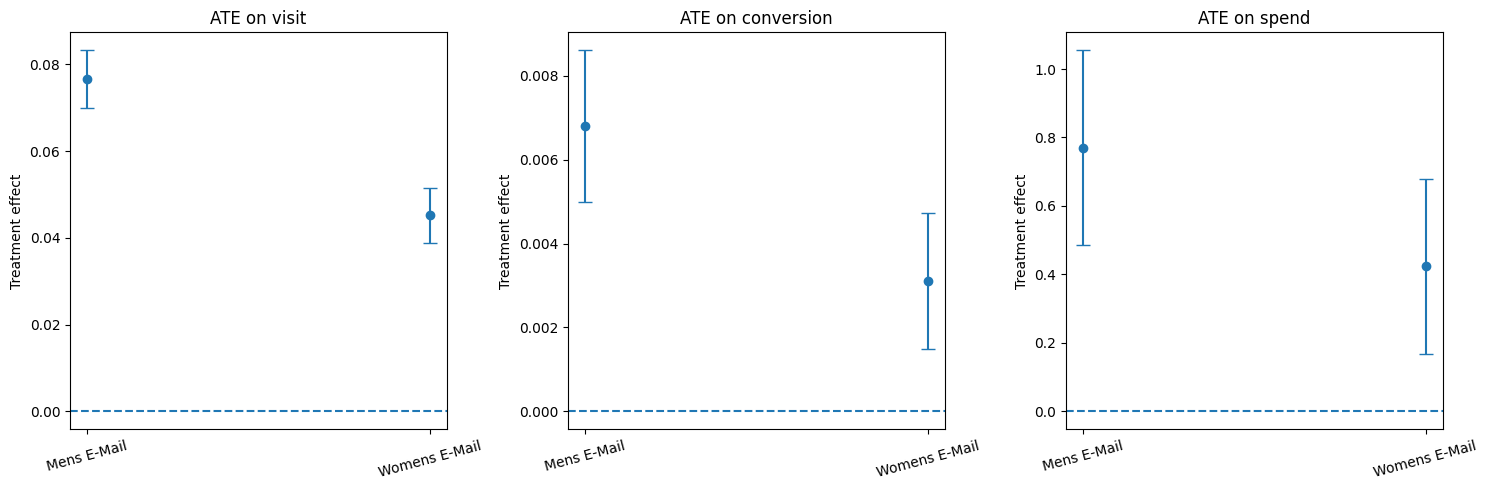

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, outcome in zip(axes, OUTCOME_COLS):
    subset = ate_table[ate_table["Outcome"] == outcome].copy()
    x = np.arange(len(subset))

    ax.errorbar(
        x,
        subset["ATE"],
        yerr=[
            subset["ATE"] - subset["CI Lower"],
            subset["CI Upper"] - subset["ATE"],
        ],
        fmt="o",
        capsize=5,
    )
    ax.axhline(0, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(subset["Treatment"], rotation=15)
    ax.set_title(f"ATE on {outcome}")
    ax.set_ylabel("Treatment effect")

plt.tight_layout()
plt.show()

## Train / Validation / Final Policy-Test Split

The original notebook used one held-out sample both to select the causal learner and to evaluate the final policy. That makes the final policy estimate optimistic because the evaluation data influenced model selection.

This revised version uses three disjoint partitions:

- **60% training** — fit candidate causal models.
- **20% validation** — compare T-Learner, X-Learner and DR-Learner and select the causal learner.
- **20% final policy test** — evaluate selected models and policies after model selection is complete.

The final test sample is never used for model fitting or causal-learner selection.

In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=df["segment"],
)

validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_df["segment"],
)

print(f"Training:   {len(train_df):,} ({len(train_df)/len(df):.0%})")
print(f"Validation: {len(validation_df):,} ({len(validation_df)/len(df):.0%})")
print(f"Final test: {len(test_df):,} ({len(test_df)/len(df):.0%})")

split_balance = pd.DataFrame({
    "Train": train_df["segment"].value_counts(normalize=True),
    "Validation": validation_df["segment"].value_counts(normalize=True),
    "Final Test": test_df["segment"].value_counts(normalize=True),
})

display(split_balance.style.format("{:.2%}"))

Training:   38,400 (60%)
Validation: 12,800 (20%)
Final test: 12,800 (20%)


,Train,Validation,Final Test
segment,,,
Mens E-Mail,33.29%,33.29%,33.30%
No E-Mail,33.29%,33.29%,33.29%
Womens E-Mail,33.42%,33.42%,33.41%


## Preprocessing — Fit on Training Data Only

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            CATEGORICAL_FEATURES,
        ),
    ],
    remainder="drop",
)

preprocessor.fit(train_df[FEATURES])

X_train_all = preprocessor.transform(train_df[FEATURES])
X_val_all = preprocessor.transform(validation_df[FEATURES])
X_test_all = preprocessor.transform(test_df[FEATURES])

feature_names = preprocessor.get_feature_names_out()

print("Encoded feature matrix:")
print("Train:", X_train_all.shape)
print("Validation:", X_val_all.shape)
print("Final test:", X_test_all.shape)

Encoded feature matrix:
Train: (38400, 18)
Validation: (12800, 18)
Final test: (12800, 18)


## Predictive Response Baseline

A response model answers **who is likely to convert**, not **who converts because of treatment**. It is included as a benchmark for later policy comparison.

In [ ]:
response_model = GradientBoostingClassifier(random_state=RANDOM_STATE)
response_model.fit(X_train_all, train_df["conversion"].to_numpy())

val_response_prob = response_model.predict_proba(X_val_all)[:, 1]
val_response_auc = roc_auc_score(validation_df["conversion"], val_response_prob)

print(f"Validation response-model ROC-AUC: {val_response_auc:.4f}")

Validation response-model ROC-AUC: 0.5993


## Causal Model Helpers

In [ ]:
def make_binary_data(data, treatment_name, outcome, fitted_preprocessor):
    subset = data[data["segment"].isin([CONTROL, treatment_name])].copy()
    X = fitted_preprocessor.transform(subset[FEATURES])
    y = subset[outcome].to_numpy(dtype=float)
    t = (subset["segment"] == treatment_name).astype(int).to_numpy()
    return subset, X, y, t


def fit_t_learner(X, y, t, outcome_type):
    if outcome_type == "binary":
        model_t = RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=20,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        model_c = clone(model_t)
    else:
        model_t = RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=20,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        model_c = clone(model_t)

    model_t.fit(X[t == 1], y[t == 1])
    model_c.fit(X[t == 0], y[t == 0])

    return {"name": "T-Learner", "treated": model_t, "control": model_c, "outcome_type": outcome_type}


def predict_t_learner(model, X):
    if model["outcome_type"] == "binary":
        mu1 = model["treated"].predict_proba(X)[:, 1]
        mu0 = model["control"].predict_proba(X)[:, 1]
    else:
        mu1 = model["treated"].predict(X)
        mu0 = model["control"].predict(X)
    return mu1 - mu0


def fit_x_learner(X, y, t, outcome_type):
    if outcome_type == "binary":
        outcome_model = RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=20,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    else:
        outcome_model = RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=20,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

    cate_model = RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=20,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    model = XLearner(models=outcome_model, cate_models=cate_model)
    model.fit(Y=y, T=t, X=X)
    return model


def fit_dr_learner(X, y, t):
    model = DRLearner(
        model_regression=RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=20,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        model_propensity=RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=20,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        model_final=RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=20,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        cv=5,
    )
    model.fit(Y=y, T=t, X=X)
    return model


def fit_candidate_models(X, y, t, outcome_type):
    return {
        "T-Learner": fit_t_learner(X, y, t, outcome_type),
        "X-Learner": fit_x_learner(X, y, t, outcome_type),
        "DR-Learner": fit_dr_learner(X, y, t),
    }


def predict_cate(model_name, model, X):
    if model_name == "T-Learner":
        return predict_t_learner(model, X)
    return np.asarray(model.effect(X)).reshape(-1)

## Transparent Qini / Incremental-Gain Evaluation

The ranking metric below sorts customers by predicted treatment effect and calculates cumulative incremental outcome relative to the randomized control group.

For binary conversion outcomes this is a Qini-style score. For continuous spend, the same construction is interpreted as **incremental-value gain area above random**, not as a binary Qini coefficient.

Scores are normalized by sample size so they are easier to compare across similarly defined evaluation samples. Model selection is always performed **within the same treatment comparison and outcome**.

In [ ]:
def cumulative_incremental_curve(y_true, treatment, score):
    curve = pd.DataFrame({
        "y": np.asarray(y_true, dtype=float),
        "treatment": np.asarray(treatment, dtype=int),
        "score": np.asarray(score, dtype=float),
    })

    curve = curve.sort_values("score", ascending=False).reset_index(drop=True)

    curve["treated_y"] = curve["y"] * curve["treatment"]
    curve["control_y"] = curve["y"] * (1 - curve["treatment"])
    curve["cum_treated"] = curve["treatment"].cumsum()
    curve["cum_control"] = (1 - curve["treatment"]).cumsum()
    curve["cum_treated_y"] = curve["treated_y"].cumsum()
    curve["cum_control_y"] = curve["control_y"].cumsum()

    expected_control = np.divide(
        curve["cum_control_y"] * curve["cum_treated"],
        curve["cum_control"],
        out=np.zeros(len(curve), dtype=float),
        where=curve["cum_control"].to_numpy() > 0,
    )

    curve["incremental_outcome"] = curve["cum_treated_y"] - expected_control
    curve["population_share"] = np.arange(1, len(curve) + 1) / len(curve)

    return curve


def normalized_area_above_random(curve):
    x = curve["population_share"].to_numpy()
    y = curve["incremental_outcome"].to_numpy()
    random_y = np.linspace(0, y[-1], len(y))

    area = np.trapezoid(y - random_y, x)
    return area / len(curve)


def plot_incremental_curve(curve, title, ylabel):
    x = curve["population_share"].to_numpy()
    y = curve["incremental_outcome"].to_numpy()
    random_y = np.linspace(0, y[-1], len(y))

    plt.figure(figsize=(9, 6))
    plt.plot(x, y, label="Causal model")
    plt.plot(x, random_y, linestyle="--", label="Random targeting")
    plt.axhline(0, linewidth=1)
    plt.title(title)
    plt.xlabel("Share of Customers Targeted")
    plt.ylabel(ylabel)
    plt.legend()
    plt.show()


def observed_uplift_by_decile(data, outcome_col, treatment_col, score, n_bins=10):
    temp = data[[outcome_col, treatment_col]].copy()
    temp["score"] = np.asarray(score)

    # rank() makes qcut robust to duplicated CATE values
    temp["decile"] = pd.qcut(
        temp["score"].rank(method="first", ascending=False),
        q=n_bins,
        labels=range(1, n_bins + 1),
    ).astype(int)

    rows = []
    for decile in range(1, n_bins + 1):
        subset = temp[temp["decile"] == decile]
        treated = subset[subset[treatment_col] == 1]
        control_group = subset[subset[treatment_col] == 0]

        rows.append({
            "Decile": decile,
            "Customers": len(subset),
            "Treated Mean": treated[outcome_col].mean(),
            "Control Mean": control_group[outcome_col].mean(),
            "Observed Uplift": treated[outcome_col].mean() - control_group[outcome_col].mean(),
            "Average Predicted CATE": subset["score"].mean(),
        })

    return pd.DataFrame(rows)

## Conversion-Uplift Model Selection on Validation Data

In [ ]:
conversion_models = {}
conversion_validation_scores = []

for treatment_name in TREATMENTS:
    train_bin, X_train_bin, y_train_bin, t_train_bin = make_binary_data(
        train_df, treatment_name, "conversion", preprocessor
    )
    val_bin, X_val_bin, y_val_bin, t_val_bin = make_binary_data(
        validation_df, treatment_name, "conversion", preprocessor
    )

    candidates = fit_candidate_models(
        X_train_bin,
        y_train_bin,
        t_train_bin,
        outcome_type="binary",
    )

    conversion_models[treatment_name] = candidates

    for model_name, model in candidates.items():
        cate = predict_cate(model_name, model, X_val_bin)
        curve = cumulative_incremental_curve(y_val_bin, t_val_bin, cate)
        score = normalized_area_above_random(curve)

        conversion_validation_scores.append({
            "Treatment": treatment_name,
            "Model": model_name,
            "Validation Qini Score": score,
        })

conversion_selection = pd.DataFrame(conversion_validation_scores)

display(
    conversion_selection
    .sort_values(["Treatment", "Validation Qini Score"], ascending=[True, False])
    .style
    .format({"Validation Qini Score": "{:.6f}"})
    .hide(axis="index")
)

Treatment,Model,Validation Qini Score
Mens E-Mail,DR-Learner,0.000498
Mens E-Mail,X-Learner,0.000197
Mens E-Mail,T-Learner,0.000125
Womens E-Mail,X-Learner,0.000433
Womens E-Mail,DR-Learner,0.000411
Womens E-Mail,T-Learner,0.000235


In [ ]:
selected_conversion_models = (
    conversion_selection
    .sort_values("Validation Qini Score", ascending=False)
    .groupby("Treatment", as_index=False)
    .first()
)

print("Selected conversion-uplift learner for each treatment:")
display(selected_conversion_models)

Selected conversion-uplift learner for each treatment:


,Treatment,Model,Validation Qini Score
0,Mens E-Mail,DR-Learner,0.0005
1,Womens E-Mail,X-Learner,0.0004


### Model-Selection Rule

The causal learner with the highest validation Qini score is selected **separately for Mens E-Mail and Womens E-Mail**. The same learner is not forced on both treatment comparisons.

The final test sample remains untouched during this selection step.

## Refit Selected Conversion Models on Training + Validation

In [ ]:
trainval_df = pd.concat([train_df, validation_df], axis=0).reset_index(drop=True)

# Refit preprocessing after model selection, using all development data.
preprocessor_final = clone(preprocessor)
preprocessor_final.fit(trainval_df[FEATURES])

X_test_final = preprocessor_final.transform(test_df[FEATURES])

final_conversion_models = {}

for treatment_name in TREATMENTS:
    selected_name = selected_conversion_models.loc[
        selected_conversion_models["Treatment"] == treatment_name,
        "Model",
    ].iloc[0]

    trainval_bin, X_trainval_bin, y_trainval_bin, t_trainval_bin = make_binary_data(
        trainval_df,
        treatment_name,
        "conversion",
        preprocessor_final,
    )

    if selected_name == "T-Learner":
        model = fit_t_learner(X_trainval_bin, y_trainval_bin, t_trainval_bin, "binary")
    elif selected_name == "X-Learner":
        model = fit_x_learner(X_trainval_bin, y_trainval_bin, t_trainval_bin, "binary")
    else:
        model = fit_dr_learner(X_trainval_bin, y_trainval_bin, t_trainval_bin)

    final_conversion_models[treatment_name] = (selected_name, model)

print("Selected conversion models refitted on training + validation data.")

Selected conversion models refitted on training + validation data.


## Final Conversion-Uplift Evaluation on Untouched Test Data

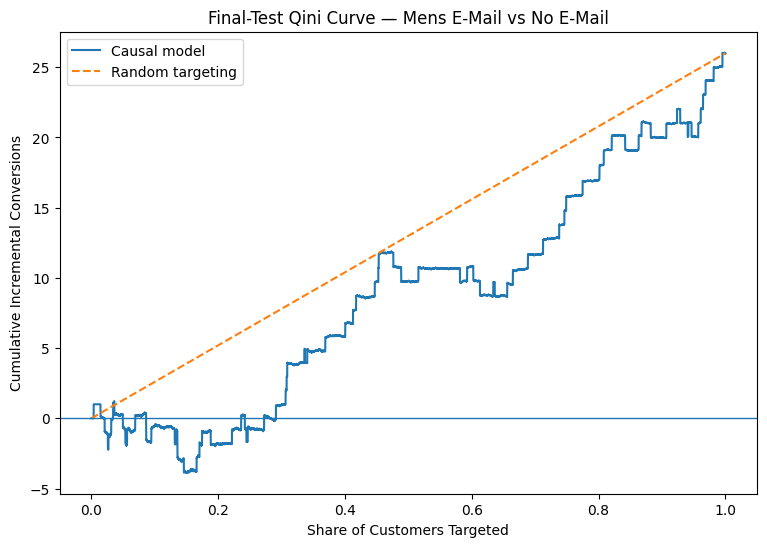

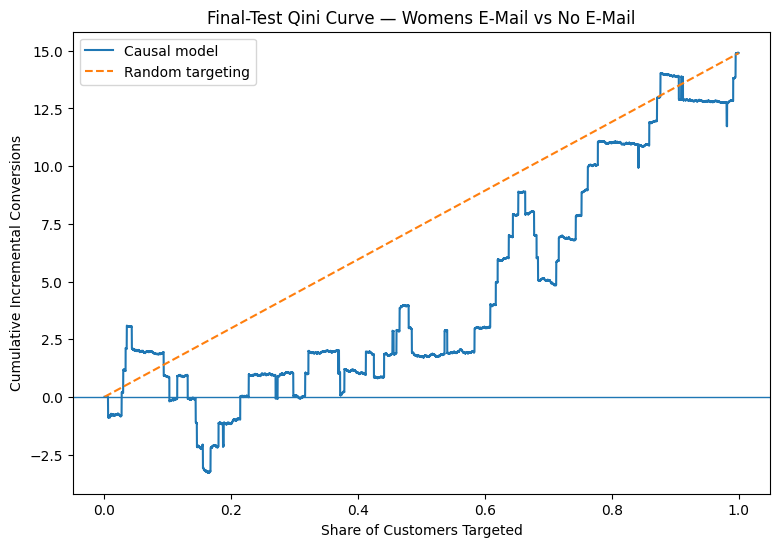

Treatment,Selected Model,Final Test Qini Score
Mens E-Mail,DR-Learner,-0.000492
Womens E-Mail,X-Learner,-0.000339


In [ ]:
test_results = test_df.copy()
conversion_test_scores = []
conversion_test_curves = {}

for treatment_name in TREATMENTS:
    test_bin, X_test_bin, y_test_bin, t_test_bin = make_binary_data(
        test_df,
        treatment_name,
        "conversion",
        preprocessor_final,
    )

    model_name, model = final_conversion_models[treatment_name]
    cate = predict_cate(model_name, model, X_test_bin)
    curve = cumulative_incremental_curve(y_test_bin, t_test_bin, cate)
    score = normalized_area_above_random(curve)

    conversion_test_scores.append({
        "Treatment": treatment_name,
        "Selected Model": model_name,
        "Final Test Qini Score": score,
    })
    conversion_test_curves[treatment_name] = curve

    plot_incremental_curve(
        curve,
        title=f"Final-Test Qini Curve — {treatment_name} vs No E-Mail",
        ylabel="Cumulative Incremental Conversions",
    )

conversion_test_table = pd.DataFrame(conversion_test_scores)

display(
    conversion_test_table.style
    .format({"Final Test Qini Score": "{:.6f}"})
    .hide(axis="index")
)

## Final-Test CATE Calibration by Decile


Mens E-Mail vs No E-Mail


Decile,Customers,Treated Mean,Control Mean,Observed Uplift,Average Predicted CATE
1,853,1.69%,1.82%,-0.13%,4.95%
2,852,0.93%,1.19%,-0.26%,2.35%
3,852,1.15%,0.48%,0.67%,1.41%
4,852,1.38%,0.24%,1.14%,0.86%
5,853,1.40%,0.47%,0.93%,0.50%
6,852,0.47%,0.23%,0.23%,0.25%
7,852,0.92%,0.72%,0.20%,0.06%
8,852,1.23%,0.00%,1.23%,-0.09%
9,852,1.18%,0.47%,0.71%,-0.50%
10,853,2.11%,0.70%,1.41%,-2.37%


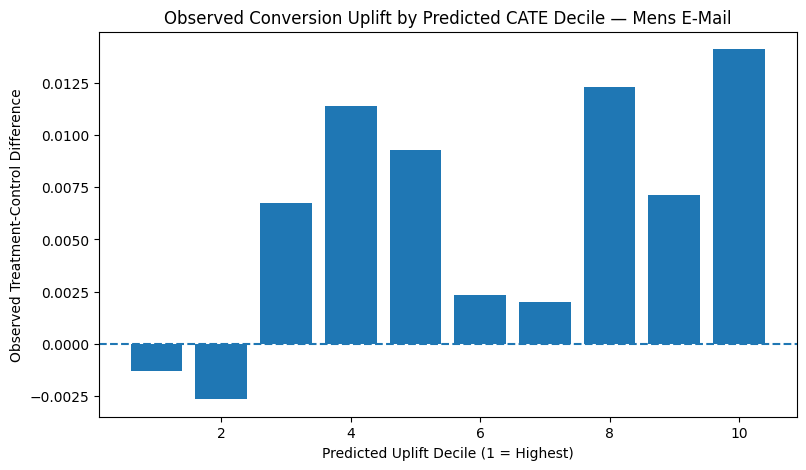


Womens E-Mail vs No E-Mail


Decile,Customers,Treated Mean,Control Mean,Observed Uplift,Average Predicted CATE
1,854,0.92%,0.72%,0.20%,1.46%
2,854,0.94%,1.40%,-0.46%,0.68%
3,854,0.72%,0.46%,0.26%,0.39%
4,853,0.94%,0.70%,0.24%,0.22%
5,854,1.13%,0.98%,0.15%,0.11%
6,854,0.49%,0.23%,0.26%,0.03%
7,853,1.41%,0.93%,0.48%,-0.01%
8,854,1.40%,0.00%,1.40%,-0.11%
9,854,0.92%,0.24%,0.68%,-0.32%
10,854,0.94%,0.70%,0.24%,-1.06%


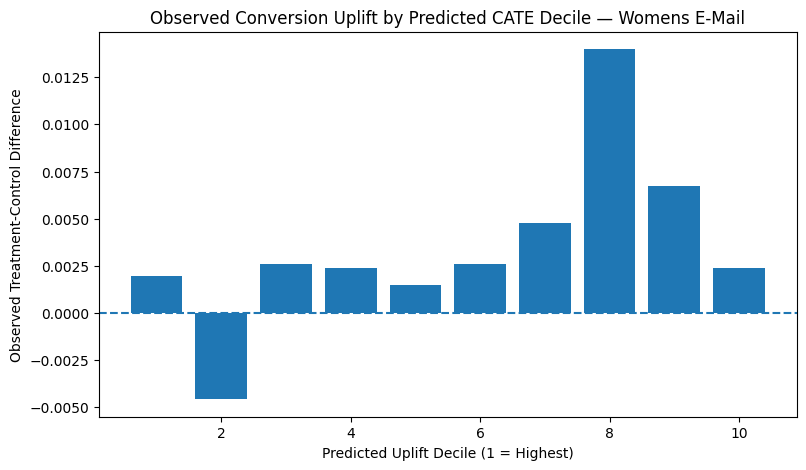

In [ ]:
conversion_cate_test = {}

for treatment_name in TREATMENTS:
    test_bin, X_test_bin, y_test_bin, t_test_bin = make_binary_data(
        test_df,
        treatment_name,
        "conversion",
        preprocessor_final,
    )
    model_name, model = final_conversion_models[treatment_name]
    cate = predict_cate(model_name, model, X_test_bin)
    conversion_cate_test[treatment_name] = (test_bin.index.to_numpy(), cate)

    temp = test_bin.copy()
    temp["treatment_binary"] = (temp["segment"] == treatment_name).astype(int)
    deciles = observed_uplift_by_decile(
        data=temp,
        outcome_col="conversion",
        treatment_col="treatment_binary",
        score=cate,
    )

    print(f"\n{treatment_name} vs No E-Mail")
    display(
        deciles.style
        .format({
            "Customers": "{:,.0f}",
            "Treated Mean": "{:.2%}",
            "Control Mean": "{:.2%}",
            "Observed Uplift": "{:.2%}",
            "Average Predicted CATE": "{:.2%}",
        })
        .hide(axis="index")
    )

    plt.figure(figsize=(9, 5))
    plt.bar(deciles["Decile"], deciles["Observed Uplift"])
    plt.axhline(0, linestyle="--")
    plt.title(f"Observed Conversion Uplift by Predicted CATE Decile — {treatment_name}")
    plt.xlabel("Predicted Uplift Decile (1 = Highest)")
    plt.ylabel("Observed Treatment-Control Difference")
    plt.show()

## Spend / Incremental-Value Model Selection

Conversion uplift and revenue uplift are different objectives. The learner that ranks conversion effects best is not assumed to be the best learner for `spend`.

Candidate models are therefore compared again on validation data using a continuous-outcome incremental-value gain score.

In [ ]:
spend_models = {}
spend_validation_scores = []

for treatment_name in TREATMENTS:
    train_bin, X_train_bin, y_train_bin, t_train_bin = make_binary_data(
        train_df, treatment_name, "spend", preprocessor
    )
    val_bin, X_val_bin, y_val_bin, t_val_bin = make_binary_data(
        validation_df, treatment_name, "spend", preprocessor
    )

    candidates = fit_candidate_models(
        X_train_bin,
        y_train_bin,
        t_train_bin,
        outcome_type="continuous",
    )

    spend_models[treatment_name] = candidates

    for model_name, model in candidates.items():
        cate = predict_cate(model_name, model, X_val_bin)
        curve = cumulative_incremental_curve(y_val_bin, t_val_bin, cate)
        score = normalized_area_above_random(curve)

        spend_validation_scores.append({
            "Treatment": treatment_name,
            "Model": model_name,
            "Validation Incremental-Value Score": score,
        })

spend_selection = pd.DataFrame(spend_validation_scores)

display(
    spend_selection
    .sort_values(
        ["Treatment", "Validation Incremental-Value Score"],
        ascending=[True, False],
    )
    .style
    .format({"Validation Incremental-Value Score": "{:.6f}"})
    .hide(axis="index")
)

Treatment,Model,Validation Incremental-Value Score
Mens E-Mail,DR-Learner,-0.007980
Mens E-Mail,T-Learner,-0.014768
Mens E-Mail,X-Learner,-0.017039
Womens E-Mail,X-Learner,0.065324
Womens E-Mail,DR-Learner,0.056603
Womens E-Mail,T-Learner,0.029151


In [ ]:
selected_spend_models = (
    spend_selection
    .sort_values("Validation Incremental-Value Score", ascending=False)
    .groupby("Treatment", as_index=False)
    .first()
)

print("Selected spend-effect learner for each treatment:")
display(selected_spend_models)

Selected spend-effect learner for each treatment:


,Treatment,Model,Validation Incremental-Value Score
0,Mens E-Mail,DR-Learner,-0.0080
1,Womens E-Mail,X-Learner,0.0653


## Refit Selected Spend Models on Training + Validation

In [ ]:
final_spend_models = {}

for treatment_name in TREATMENTS:
    selected_name = selected_spend_models.loc[
        selected_spend_models["Treatment"] == treatment_name,
        "Model",
    ].iloc[0]

    trainval_bin, X_trainval_bin, y_trainval_bin, t_trainval_bin = make_binary_data(
        trainval_df,
        treatment_name,
        "spend",
        preprocessor_final,
    )

    if selected_name == "T-Learner":
        model = fit_t_learner(X_trainval_bin, y_trainval_bin, t_trainval_bin, "continuous")
    elif selected_name == "X-Learner":
        model = fit_x_learner(X_trainval_bin, y_trainval_bin, t_trainval_bin, "continuous")
    else:
        model = fit_dr_learner(X_trainval_bin, y_trainval_bin, t_trainval_bin)

    final_spend_models[treatment_name] = (selected_name, model)

print("Selected spend models refitted on training + validation data.")

Selected spend models refitted on training + validation data.


## Final-Test Incremental Revenue Estimates

In [ ]:
X_test_final = preprocessor_final.transform(test_df[FEATURES])

for treatment_name, col_name in [
    ("Mens E-Mail", "cate_spend_mens"),
    ("Womens E-Mail", "cate_spend_womens"),
]:
    model_name, model = final_spend_models[treatment_name]
    test_results[col_name] = predict_cate(model_name, model, X_test_final)

for treatment_name, col_name in [
    ("Mens E-Mail", "cate_conversion_mens"),
    ("Womens E-Mail", "cate_conversion_womens"),
]:
    model_name, model = final_conversion_models[treatment_name]
    test_results[col_name] = predict_cate(model_name, model, X_test_final)

summary_cols = [
    "cate_conversion_mens",
    "cate_conversion_womens",
    "cate_spend_mens",
    "cate_spend_womens",
]

display(test_results[summary_cols].describe())

,cate_conversion_mens,cate_conversion_womens,cate_spend_mens,cate_spend_womens
count,"12,800.0000","12,800.0000","12,800.0000","12,800.0000"
mean,0.0074,0.0014,0.8046,0.3257
std,0.0199,0.0068,2.8344,1.7522
min,-0.1399,-0.0517,-23.3559,-13.7171
25%,-0.0008,-0.0010,-0.0968,-0.2533
50%,0.0036,0.0007,0.2991,0.1759
75%,0.0139,0.0038,1.3477,0.8287
max,0.1650,0.0500,30.6907,17.7439


## Final Spend-CATE Ranking Evaluation on Untouched Test Data

The spend-effect learners were selected using the validation sample only. Before those CATE estimates are used for profit-aware allocation, their **out-of-sample ranking performance is checked on the final randomized test sample**.

This is deliberately separate from model selection: the test scores below are diagnostic final-evaluation results and are **not used to change the selected learners**.

A positive incremental-value score means that customers ranked higher by the selected spend CATE model tend to generate stronger experimentally observed incremental spend than random targeting. A negative score indicates that the ranking did not generalize reliably to the final test sample.

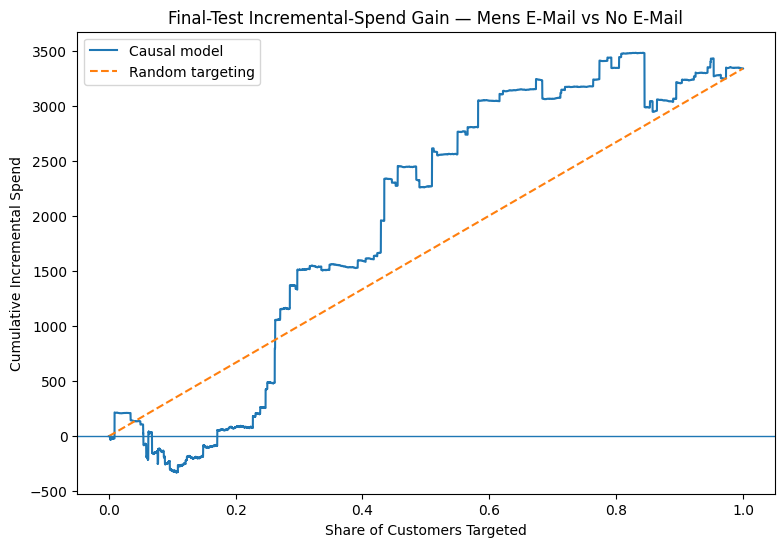

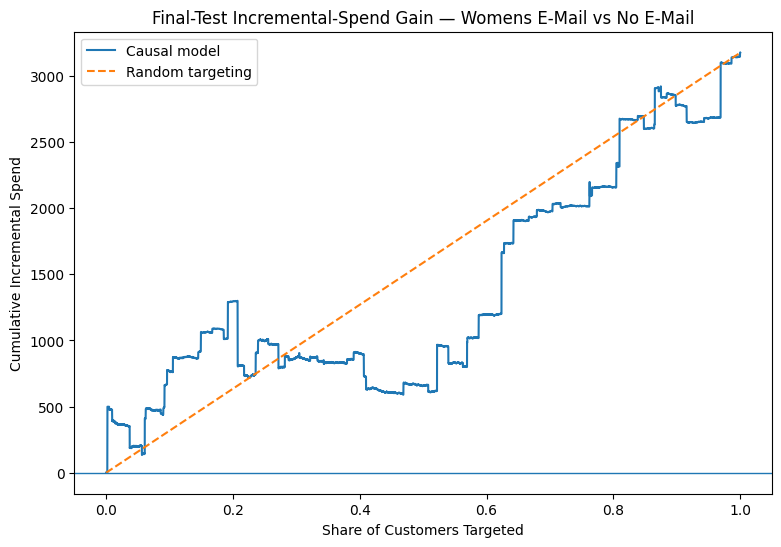

Treatment,Selected Model,Validation Incremental-Value Score,Final Test Incremental-Value Score
Mens E-Mail,DR-Learner,-0.007980,0.035679
Womens E-Mail,X-Learner,0.065324,-0.022361


In [ ]:
# =========================================================
# FINAL TEST SPEND-CATE RANKING EVALUATION
# =========================================================

spend_test_scores = []
spend_test_curves = {}

for treatment_name in TREATMENTS:
    test_bin, X_test_bin, y_test_bin, t_test_bin = make_binary_data(
        test_df,
        treatment_name,
        "spend",
        preprocessor_final,
    )

    model_name, model = final_spend_models[treatment_name]
    cate = predict_cate(model_name, model, X_test_bin)

    curve = cumulative_incremental_curve(
        y_test_bin,
        t_test_bin,
        cate,
    )
    score = normalized_area_above_random(curve)

    spend_test_scores.append({
        "Treatment": treatment_name,
        "Selected Model": model_name,
        "Validation Incremental-Value Score": selected_spend_models.loc[
            selected_spend_models["Treatment"] == treatment_name,
            "Validation Incremental-Value Score",
        ].iloc[0],
        "Final Test Incremental-Value Score": score,
    })

    spend_test_curves[treatment_name] = curve

    plot_incremental_curve(
        curve,
        title=f"Final-Test Incremental-Spend Gain — {treatment_name} vs No E-Mail",
        ylabel="Cumulative Incremental Spend",
    )

spend_test_table = pd.DataFrame(spend_test_scores)

display(
    spend_test_table.style
    .format({
        "Validation Incremental-Value Score": "{:.6f}",
        "Final Test Incremental-Value Score": "{:.6f}",
    })
    .hide(axis="index")
)

## Campaign-Cost Assumption and Profit-Aware Policy

The Hillstrom dataset does not contain delivery costs. The notebook therefore introduces explicit configurable assumptions.

These values are **scenario assumptions**, not observed properties of the original experiment.

In [ ]:
COST_MENS_EMAIL = 0.05
COST_WOMENS_EMAIL = 0.05

COST_MAP = {
    "No E-Mail": 0.00,
    "Mens E-Mail": COST_MENS_EMAIL,
    "Womens E-Mail": COST_WOMENS_EMAIL,
}

test_results["pred_profit_mens"] = test_results["cate_spend_mens"] - COST_MENS_EMAIL
test_results["pred_profit_womens"] = test_results["cate_spend_womens"] - COST_WOMENS_EMAIL


def choose_profit_treatment(row):
    values = {
        "No E-Mail": 0.0,
        "Mens E-Mail": row["pred_profit_mens"],
        "Womens E-Mail": row["pred_profit_womens"],
    }
    return max(values, key=values.get)


test_results["profit_policy_unrestricted"] = test_results.apply(
    choose_profit_treatment,
    axis=1,
)

test_results["best_predicted_profit"] = np.maximum.reduce([
    np.zeros(len(test_results)),
    test_results["pred_profit_mens"].to_numpy(),
    test_results["pred_profit_womens"].to_numpy(),
])

print("Unrestricted profit-aware treatment recommendations:")
display(test_results["profit_policy_unrestricted"].value_counts().to_frame("Customers"))

Unrestricted profit-aware treatment recommendations:


,Customers
profit_policy_unrestricted,
Mens E-Mail,5887
Womens E-Mail,4277
No E-Mail,2636


## Budget-Constrained Allocation

For a contact budget of `k%`, customers are ranked by predicted incremental profit. Only the highest-ranked customers with positive predicted profit are contacted; each selected customer receives the treatment with the larger predicted profit.

In [ ]:
def make_budget_policy(data, fraction, policy_name):
    result = pd.Series("No E-Mail", index=data.index, name=policy_name)

    n_slots = int(np.floor(len(data) * fraction))
    if n_slots <= 0:
        return result

    ranked = data.loc[data["best_predicted_profit"] > 0].sort_values(
        "best_predicted_profit",
        ascending=False,
    )

    selected_index = ranked.head(n_slots).index
    result.loc[selected_index] = data.loc[selected_index, "profit_policy_unrestricted"]

    return result


for fraction in [0.10, 0.20, 0.30, 0.50]:
    col = f"profit_policy_{int(fraction * 100)}pct"
    test_results[col] = make_budget_policy(test_results, fraction, col)

budget_policy_counts = []
for fraction in [0.10, 0.20, 0.30, 0.50]:
    col = f"profit_policy_{int(fraction * 100)}pct"
    counts = test_results[col].value_counts()
    budget_policy_counts.append({
        "Budget": fraction,
        "No E-Mail": counts.get("No E-Mail", 0),
        "Mens E-Mail": counts.get("Mens E-Mail", 0),
        "Womens E-Mail": counts.get("Womens E-Mail", 0),
    })

display(
    pd.DataFrame(budget_policy_counts)
    .style
    .format({"Budget": "{:.0%}"})
    .hide(axis="index")
)

Budget,No E-Mail,Mens E-Mail,Womens E-Mail
10%,11520,980,300
20%,10240,1780,780
30%,8960,2524,1316
50%,6400,3935,2465


## Off-Policy Evaluation on Randomized Final-Test Data

Summing predicted CATEs is **not** an unbiased estimate of realized policy value. The randomized test data allow a stronger evaluation.

For each candidate policy, inverse-propensity scoring (IPS) estimates the mean observed `spend` that would have been obtained if everyone in the test population had followed that policy. Because treatment was randomized, the assignment propensity is known from the experimental arm shares.

Net policy value subtracts the assumed email cost. Incremental profit is measured relative to the **Treat None** policy.

In [ ]:
assignment_prob = trainval_df["segment"].value_counts(normalize=True).to_dict()


def ips_policy_value(data, policy_col, outcome_col="spend"):
    assigned_prob = data["segment"].map(assignment_prob).astype(float)
    matched = (data["segment"] == data[policy_col]).astype(float)

    gross_value_per_customer = (
        matched * data[outcome_col] / assigned_prob
    ).mean()

    average_cost = data[policy_col].map(COST_MAP).mean()
    net_value_per_customer = gross_value_per_customer - average_cost

    return {
        "Gross Value / Customer": gross_value_per_customer,
        "Campaign Cost / Customer": average_cost,
        "Net Value / Customer": net_value_per_customer,
    }


def add_constant_policy(data, name, treatment):
    data[name] = treatment


add_constant_policy(test_results, "policy_none", "No E-Mail")
add_constant_policy(test_results, "policy_mens_all", "Mens E-Mail")
add_constant_policy(test_results, "policy_womens_all", "Womens E-Mail")

## Response-Model Targeting Baseline

In [ ]:
# Refit response model on all development data after causal-model selection.
response_model_final = GradientBoostingClassifier(random_state=RANDOM_STATE)
X_trainval_final = preprocessor_final.transform(trainval_df[FEATURES])
response_model_final.fit(X_trainval_final, trainval_df["conversion"].to_numpy())

test_results["response_probability"] = response_model_final.predict_proba(X_test_final)[:, 1]

# Choose the single blanket email using development-data spend ATE only.
dev_spend_effects = {}
for treatment_name in TREATMENTS:
    treated_mean = trainval_df.loc[trainval_df["segment"] == treatment_name, "spend"].mean()
    control_mean = trainval_df.loc[trainval_df["segment"] == CONTROL, "spend"].mean()
    dev_spend_effects[treatment_name] = treated_mean - control_mean

best_blanket_email = max(dev_spend_effects, key=dev_spend_effects.get)

response_top20 = pd.Series("No E-Mail", index=test_results.index)
response_top20.loc[
    test_results.nlargest(int(0.20 * len(test_results)), "response_probability").index
] = best_blanket_email

test_results["policy_response_top20"] = response_top20

print("Response-targeting baseline sends:", best_blanket_email)

Response-targeting baseline sends: Mens E-Mail


## Conversion-Uplift Targeting Baseline

In [ ]:
# Choose the treatment with the largest positive conversion CATE.
def choose_conversion_cate(row):
    values = {
        "No E-Mail": 0.0,
        "Mens E-Mail": row["cate_conversion_mens"],
        "Womens E-Mail": row["cate_conversion_womens"],
    }
    return max(values, key=values.get)


test_results["conversion_cate_policy"] = test_results.apply(
    choose_conversion_cate,
    axis=1,
)

test_results["best_conversion_cate"] = np.maximum.reduce([
    np.zeros(len(test_results)),
    test_results["cate_conversion_mens"].to_numpy(),
    test_results["cate_conversion_womens"].to_numpy(),
])

conversion_top20 = pd.Series("No E-Mail", index=test_results.index)
positive_ranked = test_results.loc[
    test_results["best_conversion_cate"] > 0
].sort_values("best_conversion_cate", ascending=False)
selected = positive_ranked.head(int(0.20 * len(test_results))).index
conversion_top20.loc[selected] = test_results.loc[selected, "conversion_cate_policy"]

test_results["policy_conversion_cate_top20"] = conversion_top20

## Final Policy Comparison

In [ ]:
policy_columns = {
    "Treat None": "policy_none",
    "Mens Email Everyone": "policy_mens_all",
    "Womens Email Everyone": "policy_womens_all",
    "Response Model Top 20%": "policy_response_top20",
    "Conversion-CATE Top 20%": "policy_conversion_cate_top20",
    "Profit-Aware Top 10%": "profit_policy_10pct",
    "Profit-Aware Top 20%": "profit_policy_20pct",
    "Profit-Aware Top 30%": "profit_policy_30pct",
    "Profit-Aware Top 50%": "profit_policy_50pct",
    "Profit-Aware Unrestricted": "profit_policy_unrestricted",
}

policy_rows = []
for policy_name, policy_col in policy_columns.items():
    value = ips_policy_value(test_results, policy_col)
    contacted = (test_results[policy_col] != "No E-Mail").sum()

    policy_rows.append({
        "Policy": policy_name,
        "Customers Contacted": contacted,
        "Contact Rate": contacted / len(test_results),
        **value,
    })

policy_table = pd.DataFrame(policy_rows)

baseline_net = policy_table.loc[
    policy_table["Policy"] == "Treat None",
    "Net Value / Customer",
].iloc[0]

policy_table["Incremental Profit / Customer"] = (
    policy_table["Net Value / Customer"] - baseline_net
)
policy_table["Estimated Incremental Profit"] = (
    policy_table["Incremental Profit / Customer"] * len(test_results)
)

display(
    policy_table.style
    .format({
        "Customers Contacted": "{:,.0f}",
        "Contact Rate": "{:.1%}",
        "Gross Value / Customer": "${:,.4f}",
        "Campaign Cost / Customer": "${:,.4f}",
        "Net Value / Customer": "${:,.4f}",
        "Incremental Profit / Customer": "${:,.4f}",
        "Estimated Incremental Profit": "${:,.2f}",
    })
    .hide(axis="index")
)

Policy,Customers Contacted,Contact Rate,Gross Value / Customer,Campaign Cost / Customer,Net Value / Customer,Incremental Profit / Customer,Estimated Incremental Profit
Treat None,0,0.0%,$0.5704,$0.0000,$0.5704,$0.0000,$0.00
Mens Email Everyone,"12,800",100.0%,$1.3544,$0.0500,$1.3044,$0.7340,"$9,395.05"
Womens Email Everyone,"12,800",100.0%,$1.3127,$0.0500,$1.2627,$0.6924,"$8,862.26"
Response Model Top 20%,"2,560",20.0%,$0.6181,$0.0100,$0.6081,$0.0378,$483.64
Conversion-CATE Top 20%,"2,560",20.0%,$0.6880,$0.0100,$0.6780,$0.1076,"$1,377.87"
Profit-Aware Top 10%,"1,280",10.0%,$0.6406,$0.0050,$0.6356,$0.0652,$834.42
Profit-Aware Top 20%,"2,560",20.0%,$0.6485,$0.0100,$0.6385,$0.0682,$872.70
Profit-Aware Top 30%,"3,840",30.0%,$0.7952,$0.0150,$0.7802,$0.2099,"$2,686.38"
Profit-Aware Top 50%,"6,400",50.0%,$1.0542,$0.0250,$1.0292,$0.4588,"$5,872.74"
Profit-Aware Unrestricted,"10,164",79.4%,$1.4252,$0.0397,$1.3855,$0.8151,"$10,433.18"


## Bootstrap Uncertainty for Policy Incremental Profit

IPS policy estimates can be noisy. The bootstrap below quantifies uncertainty for the main policies without using the test sample for further model tuning.

In [ ]:
def bootstrap_incremental_profit(
    data,
    policy_col,
    baseline_col="policy_none",
    n_boot=300,
    random_state=RANDOM_STATE,
):
    local_rng = np.random.default_rng(random_state)
    estimates = []
    n = len(data)

    for _ in range(n_boot):
        idx = local_rng.integers(0, n, size=n)
        sample = data.iloc[idx]

        policy_value = ips_policy_value(sample, policy_col)["Net Value / Customer"]
        baseline_value = ips_policy_value(sample, baseline_col)["Net Value / Customer"]
        estimates.append((policy_value - baseline_value) * n)

    estimates = np.asarray(estimates)

    return {
        "Bootstrap Mean": estimates.mean(),
        "CI Lower": np.quantile(estimates, 0.025),
        "CI Upper": np.quantile(estimates, 0.975),
    }


bootstrap_policies = {
    "Response Model Top 20%": "policy_response_top20",
    "Conversion-CATE Top 20%": "policy_conversion_cate_top20",
    "Profit-Aware Top 20%": "profit_policy_20pct",
    "Profit-Aware Unrestricted": "profit_policy_unrestricted",
}

bootstrap_rows = []
for policy_name, policy_col in bootstrap_policies.items():
    result = bootstrap_incremental_profit(test_results, policy_col)
    bootstrap_rows.append({"Policy": policy_name, **result})

bootstrap_table = pd.DataFrame(bootstrap_rows)

display(
    bootstrap_table.style
    .format({
        "Bootstrap Mean": "${:,.2f}",
        "CI Lower": "${:,.2f}",
        "CI Upper": "${:,.2f}",
    })
    .hide(axis="index")
)

Policy,Bootstrap Mean,CI Lower,CI Upper
Response Model Top 20%,$385.12,"$-2,560.17","$3,816.25"
Conversion-CATE Top 20%,"$1,200.28","$-2,034.64","$4,897.69"
Profit-Aware Top 20%,$925.91,"$-3,169.87","$5,612.54"
Profit-Aware Unrestricted,"$10,369.25","$3,223.56","$17,536.54"


## Budget Curve

Contact Budget,Customers Contacted,Estimated Incremental Profit
5%,640,"$1,771.56"
10%,"1,280",$834.42
15%,"1,920",$-83.34
20%,"2,560",$872.70
25%,"3,200","$2,384.84"
30%,"3,840","$2,686.38"
35%,"4,480","$3,821.31"
40%,"5,120","$5,529.33"
45%,"5,760","$5,917.93"
50%,"6,400","$5,872.74"


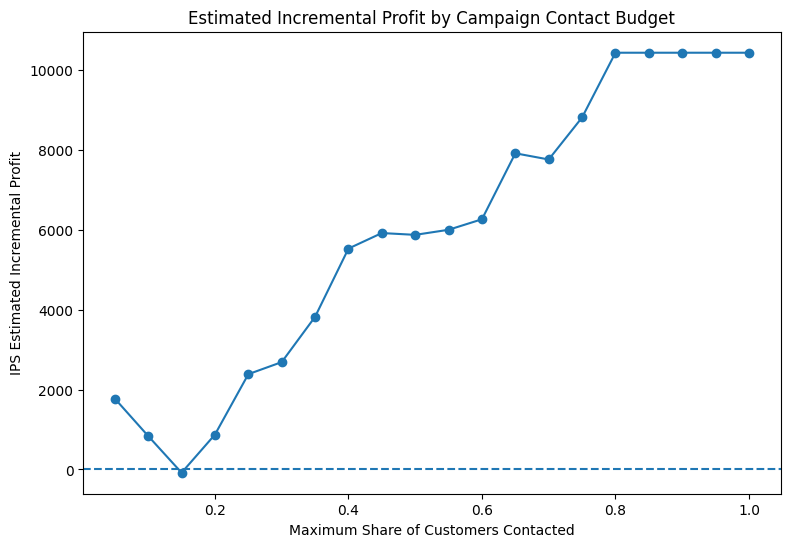

In [ ]:
budget_grid = np.arange(0.05, 1.01, 0.05)
budget_rows = []

for fraction in budget_grid:
    col = f"policy_budget_{int(round(fraction * 100)):02d}"
    test_results[col] = make_budget_policy(test_results, fraction, col)
    value = ips_policy_value(test_results, col)

    contacted = (test_results[col] != "No E-Mail").sum()
    incremental_profit = (
        value["Net Value / Customer"] - baseline_net
    ) * len(test_results)

    budget_rows.append({
        "Contact Budget": fraction,
        "Customers Contacted": contacted,
        "Estimated Incremental Profit": incremental_profit,
    })

budget_summary = pd.DataFrame(budget_rows)

display(
    budget_summary.style
    .format({
        "Contact Budget": "{:.0%}",
        "Customers Contacted": "{:,.0f}",
        "Estimated Incremental Profit": "${:,.2f}",
    })
    .hide(axis="index")
)

plt.figure(figsize=(9, 6))
plt.plot(
    budget_summary["Contact Budget"],
    budget_summary["Estimated Incremental Profit"],
    marker="o",
)
plt.axhline(0, linestyle="--")
plt.title("Estimated Incremental Profit by Campaign Contact Budget")
plt.xlabel("Maximum Share of Customers Contacted")
plt.ylabel("IPS Estimated Incremental Profit")
plt.show()

## Campaign-Cost Sensitivity

In [ ]:
def build_profit_policy_for_cost(data, cost):
    temp = data.copy()
    temp["tmp_profit_mens"] = temp["cate_spend_mens"] - cost
    temp["tmp_profit_womens"] = temp["cate_spend_womens"] - cost

    choices = []
    for _, row in temp.iterrows():
        values = {
            "No E-Mail": 0.0,
            "Mens E-Mail": row["tmp_profit_mens"],
            "Womens E-Mail": row["tmp_profit_womens"],
        }
        choices.append(max(values, key=values.get))

    return pd.Series(choices, index=temp.index)


cost_grid = [0.00, 0.02, 0.05, 0.10, 0.20, 0.50, 1.00]
cost_rows = []

original_cost_map = COST_MAP.copy()

for cost in cost_grid:
    policy_col = f"policy_cost_{str(cost).replace('.', '_')}"
    test_results[policy_col] = build_profit_policy_for_cost(test_results, cost)

    temp_cost_map = {
        "No E-Mail": 0.0,
        "Mens E-Mail": cost,
        "Womens E-Mail": cost,
    }

    assigned_prob = test_results["segment"].map(assignment_prob).astype(float)
    matched = (test_results["segment"] == test_results[policy_col]).astype(float)
    gross = (matched * test_results["spend"] / assigned_prob).mean()
    avg_cost = test_results[policy_col].map(temp_cost_map).mean()
    net = gross - avg_cost

    # Treat-none baseline does not depend on email cost.
    incremental_profit = (net - baseline_net) * len(test_results)

    cost_rows.append({
        "Cost Per Email": cost,
        "Customers Targeted": (test_results[policy_col] != "No E-Mail").sum(),
        "Estimated Incremental Profit": incremental_profit,
    })

cost_sensitivity = pd.DataFrame(cost_rows)

display(
    cost_sensitivity.style
    .format({
        "Cost Per Email": "${:.2f}",
        "Customers Targeted": "{:,.0f}",
        "Estimated Incremental Profit": "${:,.2f}",
    })
    .hide(axis="index")
)

Cost Per Email,Customers Targeted,Estimated Incremental Profit
$0.00,"10,488","$10,941.38"
$0.02,"10,387","$10,733.64"
$0.05,"10,164","$10,433.18"
$0.10,"9,824","$9,041.75"
$0.20,"9,252","$6,619.42"
$0.50,"7,641","$2,916.77"
$1.00,"5,657",$548.93


## Treatment-Effect Heterogeneity by Customer Segment

The tables below summarize **model-estimated** treatment-effect heterogeneity across observed customer groups. These are descriptive summaries of estimated CATEs and should not automatically be interpreted as causal moderator effects.

In [ ]:
for feature in ["channel", "zip_code", "newbie", "mens", "womens", "history_segment"]:
    summary = (
        test_results.groupby(feature)
        .agg(
            Customers=("segment", "size"),
            Mens_Conversion_CATE=("cate_conversion_mens", "mean"),
            Womens_Conversion_CATE=("cate_conversion_womens", "mean"),
            Mens_Spend_CATE=("cate_spend_mens", "mean"),
            Womens_Spend_CATE=("cate_spend_womens", "mean"),
        )
        .reset_index()
    )

    print(f"\nEstimated treatment heterogeneity by: {feature}")
    display(
        summary.style
        .format({
            "Customers": "{:,.0f}",
            "Mens_Conversion_CATE": "{:.2%}",
            "Womens_Conversion_CATE": "{:.2%}",
            "Mens_Spend_CATE": "${:,.3f}",
            "Womens_Spend_CATE": "${:,.3f}",
        })
        .hide(axis="index")
    )


Estimated treatment heterogeneity by: channel


channel,Customers,Mens_Conversion_CATE,Womens_Conversion_CATE,Mens_Spend_CATE,Womens_Spend_CATE
Multichannel,"1,560",1.07%,0.25%,$1.145,$0.405
Phone,"5,537",0.62%,0.08%,$0.694,$0.327
Web,"5,703",0.76%,0.16%,$0.819,$0.303



Estimated treatment heterogeneity by: zip_code


zip_code,Customers,Mens_Conversion_CATE,Womens_Conversion_CATE,Mens_Spend_CATE,Womens_Spend_CATE
Rural,"1,971",0.77%,0.15%,$1.140,$0.281
Surburban,"5,841",0.77%,0.13%,$0.765,$0.214
Urban,"4,988",0.68%,0.14%,$0.718,$0.475



Estimated treatment heterogeneity by: newbie


newbie,Customers,Mens_Conversion_CATE,Womens_Conversion_CATE,Mens_Spend_CATE,Womens_Spend_CATE
0,"6,339",0.66%,0.03%,$0.597,$-0.058
1,"6,461",0.82%,0.24%,$1.008,$0.702


... (2 outputs left out)


Estimated treatment heterogeneity by: womens


womens,Customers,Mens_Conversion_CATE,Womens_Conversion_CATE,Mens_Spend_CATE,Womens_Spend_CATE
0,"5,745",0.68%,0.02%,$0.778,$0.141
1,"7,055",0.79%,0.23%,$0.826,$0.476



Estimated treatment heterogeneity by: history_segment


history_segment,Customers,Mens_Conversion_CATE,Womens_Conversion_CATE,Mens_Spend_CATE,Womens_Spend_CATE
1) $0 - $100,"4,542",0.38%,0.16%,$0.466,$0.531
2) $100 - $200,"2,882",0.64%,0.26%,$0.860,$0.639
3) $200 - $350,"2,455",0.93%,-0.12%,$0.439,$-0.618
4) $350 - $500,"1,233",1.25%,-0.02%,$1.753,$-0.295
5) $500 - $750,"1,034",1.12%,0.38%,$1.523,$1.036
"6) $750 - $1,000",396,2.22%,0.34%,$1.604,$0.396
"7) $1,000 +",258,0.14%,0.29%,$1.000,$2.204


## Controlled-Confounding Stress Test

The randomized experiment provides a benchmark where treatment assignment is independent of customer characteristics.

To demonstrate why causal adjustment matters in observational settings, this section creates a **selected observational-like subsample** from the original randomized Mens-vs-Control development data. Selection probabilities depend jointly on treatment and pre-treatment covariates, which induces treatment-covariate imbalance while preserving each customer's actually observed randomized treatment and outcome.

The following estimators are compared with the original randomized benchmark:

- Naive treated-control difference
- Regression adjustment
- Inverse-probability weighting (IPW)
- Cross-fitted augmented inverse-probability weighting (AIPW)

This is a semi-synthetic methodological stress test, not a claim about the original Hillstrom assignment mechanism.

In [ ]:
confound_source = trainval_df[
    trainval_df["segment"].isin([CONTROL, "Mens E-Mail"])
].copy()

confound_source["treatment"] = (
    confound_source["segment"] == "Mens E-Mail"
).astype(int)

rct_benchmark = (
    confound_source.loc[confound_source["treatment"] == 1, "spend"].mean()
    - confound_source.loc[confound_source["treatment"] == 0, "spend"].mean()
)

history_z = (
    confound_source["history"] - confound_source["history"].mean()
) / confound_source["history"].std()

recency_z = (
    confound_source["recency"] - confound_source["recency"].mean()
) / confound_source["recency"].std()

selection_score = (
    0.70 * history_z
    - 0.35 * recency_z
    + 0.45 * confound_source["mens"]
    - 0.25 * confound_source["newbie"]
)

# Treated high-score customers and control low-score customers are more likely
# to remain in the observational-like sample.
signed_score = np.where(
    confound_source["treatment"].to_numpy() == 1,
    selection_score,
    -selection_score,
)

keep_probability = 0.20 + 0.75 * expit(signed_score)
keep = rng.random(len(confound_source)) < keep_probability
observational_df = confound_source.loc[keep].copy().reset_index(drop=True)

print(f"RCT development benchmark ATE on spend: ${rct_benchmark:.4f}")
print(f"Observational-like sample size: {len(observational_df):,}")
print("Treatment share in observational-like sample:")
display(observational_df["treatment"].value_counts(normalize=True).to_frame("Share"))

RCT development benchmark ATE on spend: $0.7664
Observational-like sample size: 19,569
Treatment share in observational-like sample:


,Share
treatment,
1,0.5075
0,0.4925


In [ ]:
# Preprocessing for the observational-like sample.
obs_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            CATEGORICAL_FEATURES,
        ),
    ]
)

X_obs = obs_preprocessor.fit_transform(observational_df[FEATURES])
y_obs = observational_df["spend"].to_numpy(dtype=float)
t_obs = observational_df["treatment"].to_numpy(dtype=int)

naive_obs = y_obs[t_obs == 1].mean() - y_obs[t_obs == 0].mean()

# Regression adjustment.
mu1_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=20,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
mu0_model = clone(mu1_model)
mu1_model.fit(X_obs[t_obs == 1], y_obs[t_obs == 1])
mu0_model.fit(X_obs[t_obs == 0], y_obs[t_obs == 0])
reg_adjustment = (mu1_model.predict(X_obs) - mu0_model.predict(X_obs)).mean()

# Propensity model for IPW.
propensity_model = LogisticRegression(max_iter=2000)
propensity_model.fit(X_obs, t_obs)
e_hat = np.clip(propensity_model.predict_proba(X_obs)[:, 1], 0.03, 0.97)

ipw = np.mean(
    t_obs * y_obs / e_hat
    - (1 - t_obs) * y_obs / (1 - e_hat)
)

print(f"RCT benchmark:          {rct_benchmark:.4f}")
print(f"Naive observational:    {naive_obs:.4f}")
print(f"Regression adjustment:  {reg_adjustment:.4f}")
print(f"IPW:                    {ipw:.4f}")

RCT benchmark:          0.7664
Naive observational:    1.0731
Regression adjustment:  0.8987
IPW:                    0.8534


In [ ]:
# =========================================================
# CROSS-FITTED AIPW
# =========================================================

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

mu1_hat = np.zeros(len(observational_df))
mu0_hat = np.zeros(len(observational_df))
e_hat_cf = np.zeros(len(observational_df))

for train_idx, fold_idx in skf.split(X_obs, t_obs):
    X_tr, X_fold = X_obs[train_idx], X_obs[fold_idx]
    y_tr = y_obs[train_idx]
    t_tr = t_obs[train_idx]

    prop = LogisticRegression(max_iter=2000)
    prop.fit(X_tr, t_tr)
    e_hat_cf[fold_idx] = np.clip(prop.predict_proba(X_fold)[:, 1], 0.03, 0.97)

    m1 = RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=20,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    m0 = clone(m1)

    m1.fit(X_tr[t_tr == 1], y_tr[t_tr == 1])
    m0.fit(X_tr[t_tr == 0], y_tr[t_tr == 0])

    mu1_hat[fold_idx] = m1.predict(X_fold)
    mu0_hat[fold_idx] = m0.predict(X_fold)

pseudo_outcome = (
    mu1_hat
    - mu0_hat
    + t_obs * (y_obs - mu1_hat) / e_hat_cf
    - (1 - t_obs) * (y_obs - mu0_hat) / (1 - e_hat_cf)
)

aipw = pseudo_outcome.mean()

confounding_comparison = pd.DataFrame({
    "Estimator": [
        "Randomized benchmark",
        "Naive observational difference",
        "Regression adjustment",
        "IPW",
        "Cross-fitted AIPW",
    ],
    "Estimated Spend Effect": [
        rct_benchmark,
        naive_obs,
        reg_adjustment,
        ipw,
        aipw,
    ],
})

confounding_comparison["Absolute Error vs RCT"] = (
    confounding_comparison["Estimated Spend Effect"] - rct_benchmark
).abs()

display(
    confounding_comparison.style
    .format({
        "Estimated Spend Effect": "${:.4f}",
        "Absolute Error vs RCT": "${:.4f}",
    })
    .hide(axis="index")
)

Estimator,Estimated Spend Effect,Absolute Error vs RCT
Randomized benchmark,$0.7664,$0.0000
Naive observational difference,$1.0731,$0.3068
Regression adjustment,$0.8987,$0.1324
IPW,$0.8534,$0.0870
Cross-fitted AIPW,$0.8602,$0.0939


## Final Model Selection and Policy Evaluation Summary

After the notebook has run successfully, the tables above should be interpreted in this order:

1. **Experimental ATEs** establish whether each email has an average causal effect.
2. **Validation-set model selection** chooses the heterogeneous treatment-effect learner for each treatment and outcome.
3. **Final-test Qini / gain curves** assess whether the selected model ranks treatment effects on data excluded from model selection.
4. **Profit-aware allocation** converts spend CATEs into treatment recommendations under explicit campaign-cost assumptions.
5. **IPS policy evaluation** uses randomized final-test outcomes to estimate policy value rather than simply summing model predictions.
6. **Bootstrap intervals** quantify uncertainty around key policy comparisons.
7. **Controlled confounding** demonstrates why observational causal adjustment may be needed when randomization is lost.

The final-test conversion and spend ranking scores are **evaluation diagnostics only**. They are not used to re-select models after observing the test sample.

In [ ]:
# Compact final model-selection and evaluation summary.
final_model_summary = pd.DataFrame({
    "Treatment": TREATMENTS,
    "Conversion Learner": [
        selected_conversion_models.loc[
            selected_conversion_models["Treatment"] == t,
            "Model",
        ].iloc[0]
        for t in TREATMENTS
    ],
    "Validation Conversion Qini": [
        selected_conversion_models.loc[
            selected_conversion_models["Treatment"] == t,
            "Validation Qini Score",
        ].iloc[0]
        for t in TREATMENTS
    ],
    "Final Test Conversion Qini": [
        conversion_test_table.loc[
            conversion_test_table["Treatment"] == t,
            "Final Test Qini Score",
        ].iloc[0]
        for t in TREATMENTS
    ],
    "Spend Learner": [
        selected_spend_models.loc[
            selected_spend_models["Treatment"] == t,
            "Model",
        ].iloc[0]
        for t in TREATMENTS
    ],
    "Validation Spend Gain Score": [
        selected_spend_models.loc[
            selected_spend_models["Treatment"] == t,
            "Validation Incremental-Value Score",
        ].iloc[0]
        for t in TREATMENTS
    ],
    "Final Test Spend Gain Score": [
        spend_test_table.loc[
            spend_test_table["Treatment"] == t,
            "Final Test Incremental-Value Score",
        ].iloc[0]
        for t in TREATMENTS
    ],
})

display(
    final_model_summary.style
    .format({
        "Validation Conversion Qini": "{:.6f}",
        "Final Test Conversion Qini": "{:.6f}",
        "Validation Spend Gain Score": "{:.6f}",
        "Final Test Spend Gain Score": "{:.6f}",
    })
    .hide(axis="index")
)

best_policy_row = policy_table.sort_values(
    "Estimated Incremental Profit",
    ascending=False,
).iloc[0]

print("Best final-test policy by IPS estimated incremental profit:")
print(best_policy_row["Policy"])
print(
    f"Estimated incremental profit: "
    f"${best_policy_row['Estimated Incremental Profit']:,.2f}"
)

Treatment,Conversion Learner,Validation Conversion Qini,Final Test Conversion Qini,Spend Learner,Validation Spend Gain Score,Final Test Spend Gain Score
Mens E-Mail,DR-Learner,0.000498,-0.000492,DR-Learner,-0.007980,0.035679
Womens E-Mail,X-Learner,0.000433,-0.000339,X-Learner,0.065324,-0.022361


Best final-test policy by IPS estimated incremental profit:
Profit-Aware Unrestricted
Estimated incremental profit: $10,433.18


## Conclusion

This project demonstrates how randomized experimental data can be extended
from average treatment-effect estimation into a causal decision framework
for marketing allocation.

The Hillstrom experiment shows positive average causal effects for both email
treatments. Mens E-Mail produced the larger average effect, increasing
conversion by approximately **0.68 percentage points** and spend by
approximately **\$0.77 per customer** relative to No E-Mail.

Womens E-Mail also produced positive average effects, increasing conversion
by approximately **0.31 percentage points** and spend by approximately
**\$0.42 per customer**.

Heterogeneous treatment-effect learners were compared using a dedicated
validation sample and selected separately for each treatment and outcome.

For conversion uplift, the selected models did not generalize strongly to the
untouched final test sample. The Mens DR-Learner achieved a final-test Qini
score of approximately **-0.000492**, while the Womens X-Learner achieved
approximately **-0.000339**.

These results indicate that individual-level conversion-uplift ranking was
unstable out of sample.

Spend-effect ranking was also mixed. The selected Mens DR-Learner improved from
a validation incremental-value score of approximately **-0.0080** to a
positive final-test score of approximately **0.0357**.

In contrast, the Womens X-Learner moved from approximately **0.0653** on
validation to approximately **-0.0224** on the final test.

This reinforces the importance of evaluating heterogeneous treatment-effect
models on data excluded from model selection.

Despite this instability in individual CATE rankings, the final randomized
policy evaluation produced a meaningful business result.

Under the assumed **\$0.05 email-delivery cost**, the highest IPS-estimated
incremental profit was achieved by the **unrestricted profit-aware causal
policy**, which generated approximately **\$10,433** across the
12,800-customer final test sample while contacting about **79% of customers**.

### Policy Comparison

- **Profit-Aware Unrestricted:** approximately **\$10,433**
- **Mens Email Everyone:** approximately **\$9,395**
- **Womens Email Everyone:** approximately **\$8,862**
- **Profit-Aware Top 50%:** approximately **\$5,873**
- **Conversion-CATE Top 20%:** approximately **\$1,378**
- **Profit-Aware Top 20%:** approximately **\$873**
- **Response-Model Top 20%:** approximately **\$484**

The unrestricted profit-aware policy also produced a bootstrap mean
incremental profit of approximately **\$10,369**, with a 95% bootstrap
interval of approximately **\$3,224 to \$17,537**.

The result therefore does not imply that more complex causal models are always
better. Instead, it shows that combining estimated incremental spend with
explicit treatment costs can produce a useful allocation rule, while the
quality of individual treatment-effect ranking itself remains uncertain.

The controlled-confounding experiment provides an additional causal-inference
lesson. After deliberately introducing treatment-selection bias, the naive
observational estimate overstated the randomized spend effect.

Regression adjustment, inverse-propensity weighting and cross-fitted AIPW all
moved the estimate closer to the randomized benchmark.

Overall, the project separates:

- prediction from causality,
- model selection from final evaluation,
- average treatment effects from heterogeneous treatment effects,
- treatment-effect estimation from policy optimization,
- predicted policy value from experimentally grounded off-policy evaluation.

The main business conclusion is that causal policy optimization can add value
beyond blanket targeting, but only when its recommendations are evaluated
against simple experimental baselines on genuinely held-out randomized data.

## Limitations

- The Hillstrom experiment is historical and may not represent current digital marketing behaviour.
- The observed outcomes cover a short post-treatment window rather than long-term customer lifetime value.
- Campaign delivery cost is not observed and is introduced as an explicit scenario assumption.
- Individual treatment effects are never directly observed; CATE quality is assessed through held-out ranking and grouped randomized outcomes.
- The final test evaluates generalisation within the same historical experimental population, not across future time periods.
- IPS policy estimates can be noisy when relatively few test observations happen to receive the same treatment recommended by a policy; bootstrap intervals are therefore reported.
- Model-estimated CATE differences across customer segments should not automatically be interpreted as causal moderator effects.
- The controlled-confounding section is semi-synthetic and is intended as a methodological stress test, not as a claim that the original experiment was confounded.
- Profit optimization considers immediate observed spend and email cost, not inventory constraints, channel capacity, customer fatigue or long-term brand effects.

## Optional Output Exports

Run this cell after the notebook is complete if you want compact CSV artifacts for the GitHub repository.

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

ate_table.to_csv(OUTPUT_DIR / "ate_results.csv", index=False)
conversion_selection.to_csv(OUTPUT_DIR / "conversion_model_selection.csv", index=False)
spend_selection.to_csv(OUTPUT_DIR / "spend_model_selection.csv", index=False)
policy_table.to_csv(OUTPUT_DIR / "policy_comparison.csv", index=False)
budget_summary.to_csv(OUTPUT_DIR / "budget_policy_results.csv", index=False)
confounding_comparison.to_csv(OUTPUT_DIR / "confounding_stress_test.csv", index=False)

print(f"Outputs written to: {OUTPUT_DIR.resolve()}")

Outputs written to: /content/outputs


## Reproducibility

In [ ]:
import sklearn
import econml
import scipy
import matplotlib

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy:", scipy.__version__)
print("matplotlib:", matplotlib.__version__)
print("econml:", econml.__version__)

Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
pandas: 2.2.3
numpy: 2.1.3
scikit-learn: 1.6.1
scipy: 1.16.3
matplotlib: 3.10.0
econml: 0.17.0


## Recommended Repository Structure

```text
Causal-Marketing-Allocation/
├── README.md
├── causal_marketing_allocation.ipynb
├── requirements.txt
├── data/
│   └── hillstrom.csv
└── outputs/
    ├── ate_results.csv
    ├── model_selection.csv
    ├── policy_comparison.csv
    └── budget_policy_results.csv
```

For a public GitHub version, the notebook can continue loading the source data from a stable public URL, or the dataset can be stored under `data/` if licensing and repository-size constraints allow it.